In [1]:
import logging
logging.captureWarnings(True)

In [2]:
import numpy as np
import networkx as nx

In [3]:
from multifractal_networks.mfng import MultifractalNetworkGenerator
from multifractal_networks.mfnf import MultifractalNetworkFitter

# Generating the network

In [4]:
N = 10000
m = 3
k = 4

In [5]:
P = np.array([
    [0.28496249, 0.46450071, 0.3449749 ],
    [0.46450071, 0.00946877, 0.39117118],
    [0.34497490, 0.39117118, 0.05582052]
])
l = np.array(
    [0.08283585, 0.59124287, 0.32592127]
)

In [6]:
generator = MultifractalNetworkGenerator(P,l,k,N,num_workers=-1)

Initializing...
0.0011527538299560547


In [7]:
generator()
print(2 * generator.G.number_of_edges() / generator.G.number_of_nodes())

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:18<00:00,  1.69it/s]


Refining network structure...
26.673


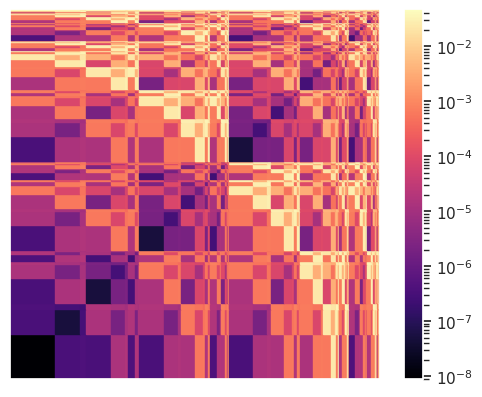

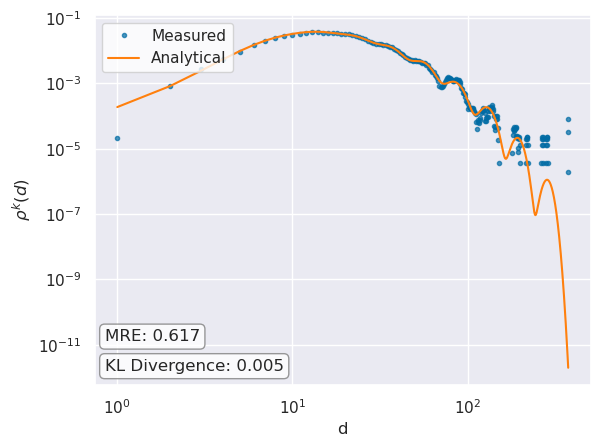

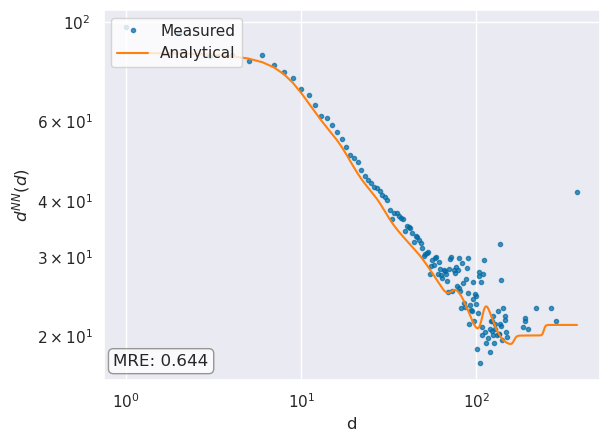

Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:11.419347
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:12:15.360420


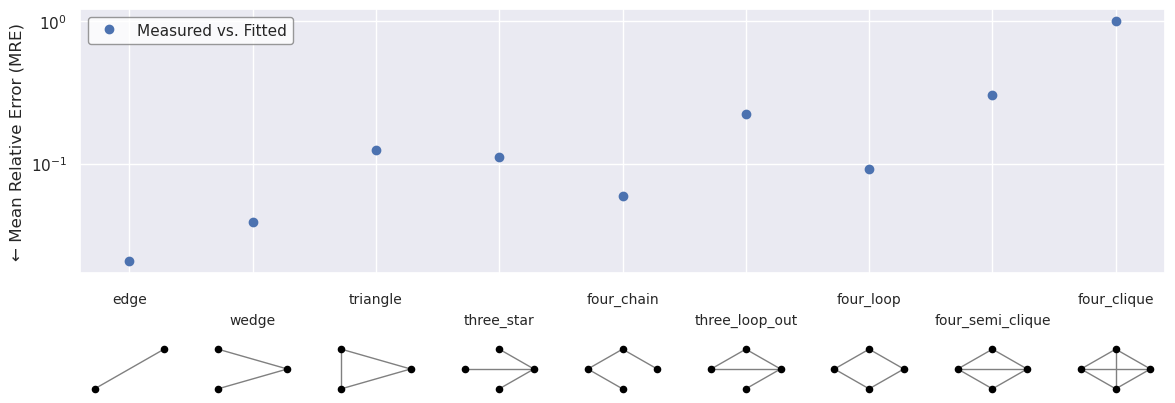

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'analytical_count': 130603.28824809701,
  'count': 133365,
  'MRE': 0.020707920008270424},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'analytical_count': 5119232.830449448,
  'count': 5326342,
  'MRE': 0.038883941277250325},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'analytical_count': 1332.0445895672015,
  'count': 1521,
  'MRE': 0.12423103907481824},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'analytical_count': 101951717.60639928,
  'count': 114630768,
  'MRE': 0.11060774183769508},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'analytical_count': 161590725.46722203,
  'count': 171695

In [8]:
#generator.plot_generated_network(
#    layout_func = nx.spring_layout,
#    largest_component_only = False,
#)

generator.network_stats(
    log_scale = True,
    filename="figures/synthetic_network_10k_plot_ground_truth.pdf",
    motif_analyzer_args = {
        'exact': True,
        'bootstrap_iters': None,
        'ci': None
    }
)

generator.motifs

In [9]:
generator.save_network('./test_networks/synthetic_network_10k.graphml')

---

# Fitting

## Load, count motifs

In [10]:
filename = './test_networks/synthetic_network_10k.graphml'
G = nx.read_graphml(filename)

In [11]:
for m_size in [2,3,5]:
    print(m_size,' k_max: ',int(np.log(len(G))/np.log(m_size**2))+1)

2  k_max:  7
3  k_max:  5
5  k_max:  3
6  k_max:  3
7  k_max:  3


In [12]:
mfnf = MultifractalNetworkFitter(G,
                                 #d_range = [1,200],
                                 motifs = [
                                     {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
                                     {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
                                     {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
                                     {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
                                 ],
                                 sampling_ratios = {3: None,
                                                    4: None},
                                 motif_analyzer_args={'exact': True, 'bootstrap_iters': None, 'ci': None},
                                 population_size = 100,
                                 weights = {'rho':9,
                                            'deg_nn':9,
                                            'motifs':1,
                                            'edge':9},
                                 pre_loaded_motifs = None
                                )

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:11.633630
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:12:16.604581


In [13]:
mfnf.save_motifs('./test_networks/synthetic_network_10k_motifs.pkl')

## Grid Search - Find m,k,P,l together

In [14]:
mfnf.find_m_k_P_l(
    m_k_dict = [{'m': 2,   'k': [1,7]},
                {'m': 3,   'k': [1,5]},
                {'m': 5,   'k': [1,3]},
               ],
    n_trials = None,
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = False,
    grid_search = True,
    optimize_for = 'kl_energy'
)

[I 2025-02-11 10:39:22,404] A new study created in memory with name: no-name-861bdc7a-ef03-4194-b048-f5e867818575


Grid Search requires 6 trials...


[I 2025-02-11 10:39:44,427] Trial 0 finished with value: 4.590799089677137 and parameters: {'m': 2, 'k': 6}. Best is trial 0 with value: 4.590799089677137.
[I 2025-02-11 10:40:00,545] Trial 1 finished with value: 5.950397836178609 and parameters: {'m': 2, 'k': 3}. Best is trial 0 with value: 4.590799089677137.
[I 2025-02-11 10:40:14,702] Trial 2 finished with value: 8.424367330032712 and parameters: {'m': 2, 'k': 2}. Best is trial 0 with value: 4.590799089677137.
[I 2025-02-11 10:40:30,806] Trial 3 finished with value: 5.339847143384271 and parameters: {'m': 2, 'k': 4}. Best is trial 0 with value: 4.590799089677137.
[I 2025-02-11 10:40:46,190] Trial 4 finished with value: 17.650068344538713 and parameters: {'m': 2, 'k': 1}. Best is trial 0 with value: 4.590799089677137.
[I 2025-02-11 10:41:06,089] Trial 5 finished with value: 4.939684138115344 and parameters: {'m': 2, 'k': 5}. Best is trial 0 with value: 4.590799089677137.
[I 2025-02-11 10:41:06,090] A new study created in memory with 

Grid Search requires 4 trials...


[I 2025-02-11 10:41:36,598] Trial 0 finished with value: 2.398300726082023 and parameters: {'m': 3, 'k': 3}. Best is trial 0 with value: 2.398300726082023.
[I 2025-02-11 10:42:26,100] Trial 1 finished with value: 2.1507967061526756 and parameters: {'m': 3, 'k': 4}. Best is trial 1 with value: 2.1507967061526756.
[I 2025-02-11 10:42:53,404] Trial 2 finished with value: 3.660474921855344 and parameters: {'m': 3, 'k': 2}. Best is trial 1 with value: 2.1507967061526756.
[I 2025-02-11 10:43:12,543] Trial 3 finished with value: 13.226103806646954 and parameters: {'m': 3, 'k': 1}. Best is trial 1 with value: 2.1507967061526756.
[I 2025-02-11 10:43:12,544] A new study created in memory with name: no-name-3a2bd8d3-8e9e-41fc-81d6-04f87b057383


Grid Search requires 2 trials...


[I 2025-02-11 10:43:51,174] Trial 0 finished with value: 2.7686400611112645 and parameters: {'m': 5, 'k': 2}. Best is trial 0 with value: 2.7686400611112645.
[I 2025-02-11 10:44:21,889] Trial 1 finished with value: 14.815258684588342 and parameters: {'m': 5, 'k': 1}. Best is trial 0 with value: 2.7686400611112645.


Best parameters:  {'m': 3, 'k': 4}
Best energy:  7.663414883870269
Best KL-divergence:  0.0049398025649123635
Best KLD augumented energy: 2.1507967061526756
Best P matrix:
 [[0.00317135 0.39120091 0.43395635]
 [0.39120091 0.0465442  0.38251698]
 [0.43395635 0.38251698 0.33743876]]
Best l vector:
 [0.57776803 0.33169506 0.09053691]


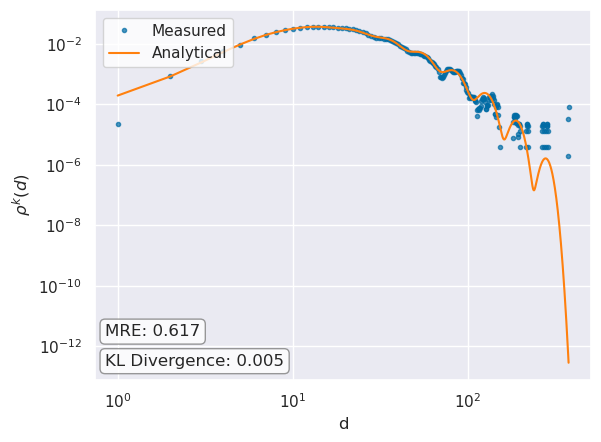

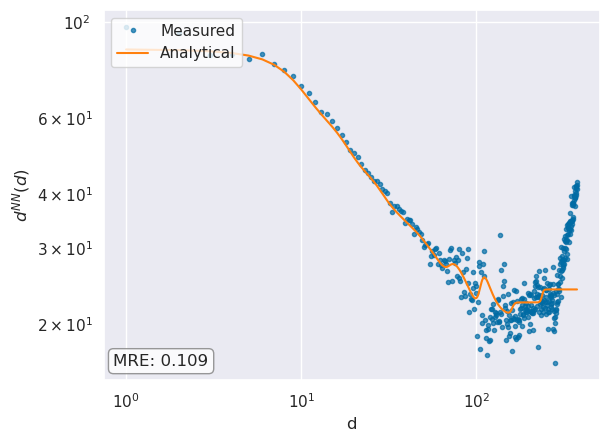

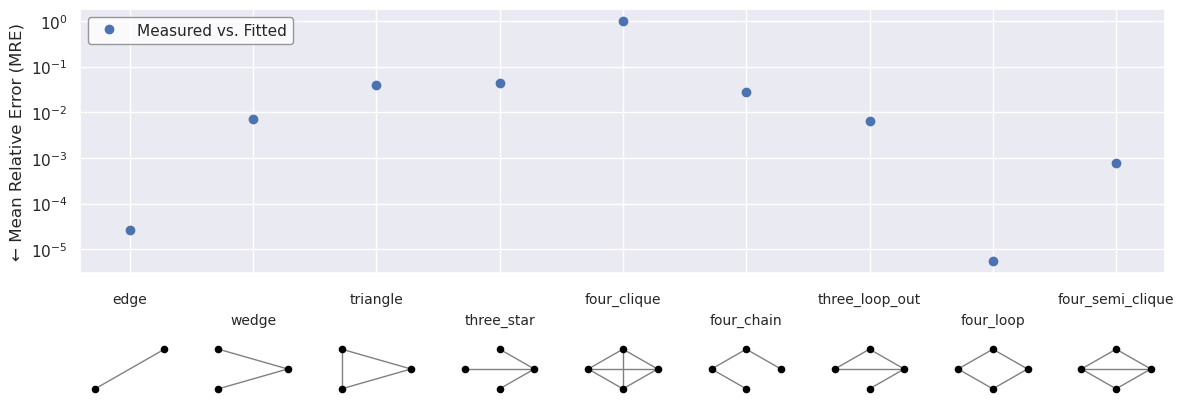

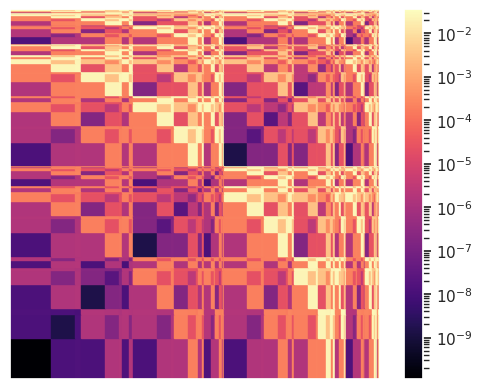

In [15]:
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_10k_plot.pdf"
)

---

## Bootstrapping stability

In [16]:
mfnf.bootstrap_P_l_stability(
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = True,
    resample_size = mfnf.population_size * 10,
    ci = 0.95,
    medoid = 'mean'
)

Gathering statistics (300 runs)...


100%|██████████| 300/300 [3:57:42<00:00, 47.54s/it]  

Bootstrapping: Resampling 1000 times...


Bootstrapping finished in 0:00:00.687380
Energy = 7.67 (7.65, 7.74)
l = [0.58 (0.57, 0.62), 0.33 (0.28, 0.34), 0.09 (0.08, 0.10)]
P = [
[0.01 (0.00, 0.03), 0.39 (0.39, 0.40), 0.45 (0.43, 0.47)],

[0.39 (0.39, 0.40), 0.05 (0.00, 0.08), 0.34 (0.24, 0.39)],

[0.45 (0.43, 0.47), 0.34 (0.24, 0.39), 0.41 (0.33, 0.54)]
]


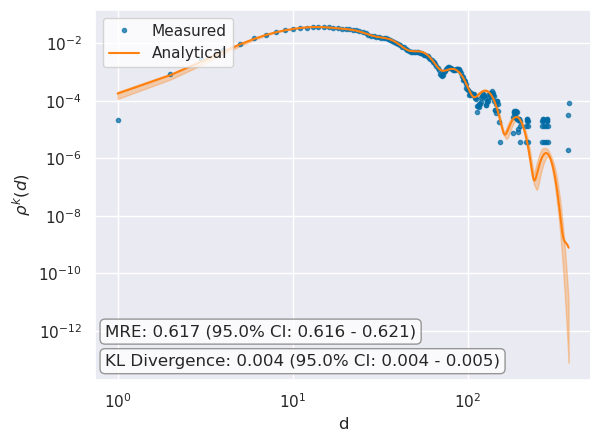

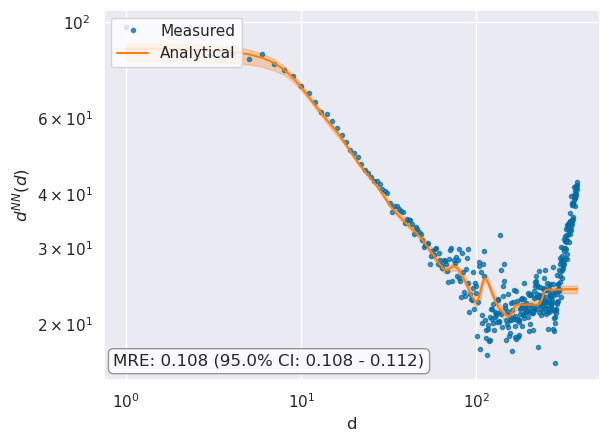

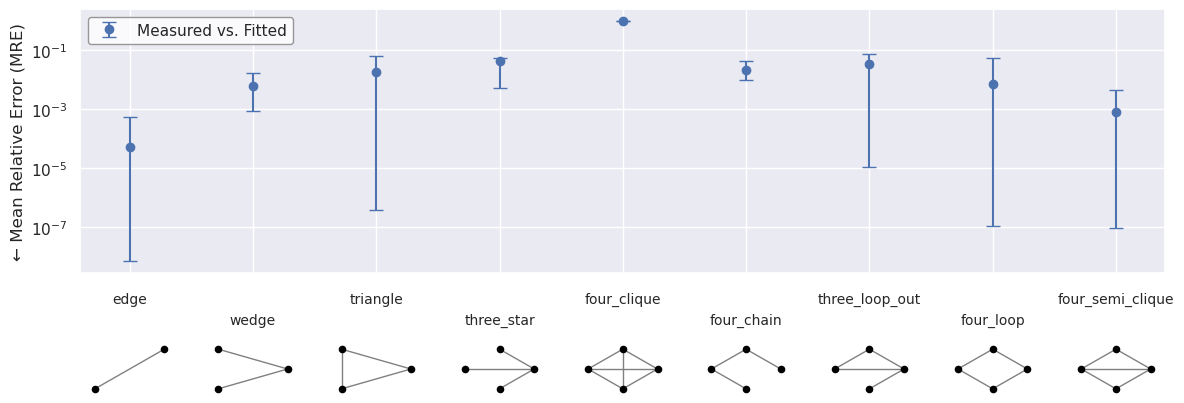

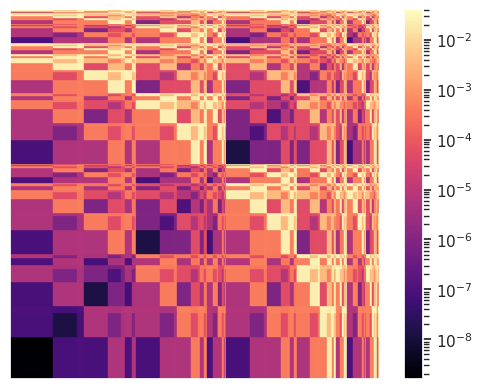

In [17]:
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_10k_plot_bootstrap.pdf"
)